In [ ]:
# ============================================================
# 🌱 CLASSIFICAÇÃO DE ESTÁGIOS DA SOJA — FINE-TUNING PARCIAL
# Modelos: ResNet50 / EfficientNetV2 / ViT / SWIN TRANSFORMER / CONVNEXT
# ============================================================

!pip install torch torchvision timm scikit-learn joblib -q
import os
import torch
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler
from collections import Counter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt


from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = "/content/drive/MyDrive/VNT - Sistemas/ZeraBank/imagens_agrupadas_384"
SAVE_PATH = "/content/drive/MyDrive/VNT - Sistemas/ZeraBank/modelo/modeloZera"
os.makedirs(SAVE_PATH, exist_ok=True)

BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Usando dispositivo:", DEVICE)


Mounted at /content/drive
Usando dispositivo: cuda


In [ ]:
transform_aug = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop((224, 224), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.GaussianBlur(kernel_size=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

In [ ]:
# Dataset com augmentation
dataset = datasets.ImageFolder(DATASET_PATH)
class_names = dataset.classes
targets = dataset.targets
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

train_idx, val_idx = train_test_split(
    range(len(targets)),
    test_size=0.2,
    stratify=targets,
    random_state=42
)
train_dataset = datasets.ImageFolder(DATASET_PATH, transform=transform_aug)
val_dataset   = datasets.ImageFolder(DATASET_PATH, transform=transform_val)

train_dataset = Subset(train_dataset, train_idx)
val_dataset   = Subset(val_dataset, val_idx)

train_targets = [targets[i] for i in train_idx]
counts = Counter(train_targets)

class_counts = np.array([counts[i] for i in range(len(class_names))])
class_weights = 1.0 / class_counts

sample_weights = [class_weights[label] for label in train_targets]
sample_weights = torch.DoubleTensor(sample_weights)

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)


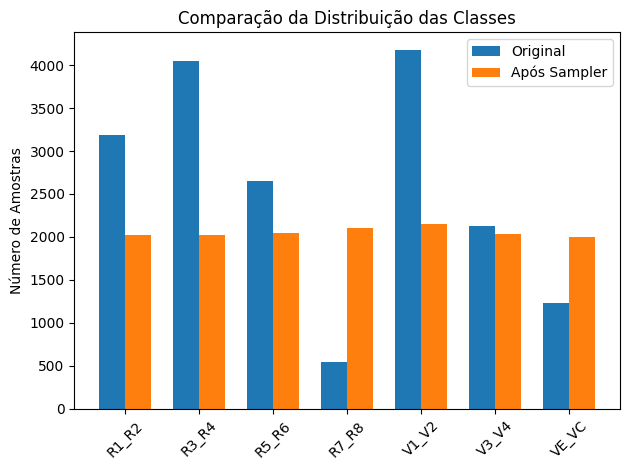

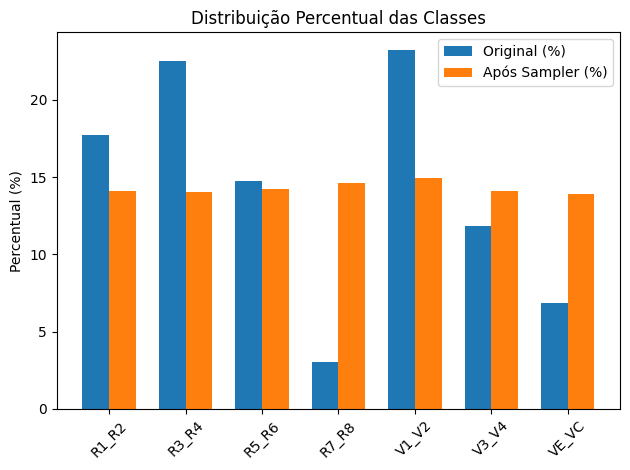

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Distribuição original
original_counts = Counter(targets)
original_values = [original_counts[i] for i in range(len(class_names))]

# Distribuição após sampler (simulação de 1 época)
sampled_labels = []
for idx in list(sampler):
    sampled_labels.append(train_targets[idx])

sampled_counts = Counter(sampled_labels)
sampled_values = [sampled_counts[i] for i in range(len(class_names))]

# Configuração do gráfico
x = np.arange(len(class_names))
width = 0.35

plt.figure()
plt.bar(x - width/2, original_values, width, label="Original")
plt.bar(x + width/2, sampled_values, width, label="Após Sampler")

plt.xticks(x, class_names, rotation=45)
plt.ylabel("Número de Amostras")
plt.title("Comparação da Distribuição das Classes")
plt.legend()
plt.tight_layout()
plt.show()
# Converter para percentual
original_percent = np.array(original_values) / sum(original_values) * 100
sampled_percent = np.array(sampled_values) / sum(sampled_values) * 100

plt.figure()
plt.bar(x - width/2, original_percent, width, label="Original (%)")
plt.bar(x + width/2, sampled_percent, width, label="Após Sampler (%)")

plt.xticks(x, class_names, rotation=45)
plt.ylabel("Percentual (%)")
plt.title("Distribuição Percentual das Classes")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    scaler = GradScaler()

    total_loss = 0
    correct = 0
    total = 0

    loop = tqdm(loader, desc=f"Epoch", leave=False, dynamic_ncols=True)

    for imgs, labels in loop:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()

        with autocast():
            outputs = model(imgs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        # Atualiza barra de progresso corretamente
        loop.set_postfix(loss=loss.item())

    return total_loss / total, correct / total


In [ ]:
#VISION TRANSFORMER (ViT) — Fine-Tuning Parcial
import timm

vit = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=len(class_names))
vit = vit.to(DEVICE)

for name, param in vit.named_parameters():
    if "head" not in name:
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(vit.head.parameters(), lr=1e-3)

history_vit = {"loss": [], "acc": []}

for epoch in range(1, 11):
    loss, acc = train_epoch(vit, train_loader, criterion, optimizer)
    history_vit["loss"].append(loss)
    history_vit["acc"].append(acc)
    print(f"[ViT] Epoch {epoch} — Loss: {loss:.4f} — Acc: {acc:.4f}")

torch.save(vit.state_dict(), f"{SAVE_PATH}/vit_modeloZera_group.pth")
print("\n✅ ViT salvo!")


/tmp/ipython-input-3664916282.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch:   0%|          | 0/450 [00:00<?, ?it/s]/tmp/ipython-input-3664916282.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[ViT] Epoch 1 — Loss: 0.3928 — Acc: 0.8567


[ViT] Epoch 2 — Loss: 0.2243 — Acc: 0.9220


[ViT] Epoch 3 — Loss: 0.1884 — Acc: 0.9327


[ViT] Epoch 4 — Loss: 0.1806 — Acc: 0.9352


[ViT] Epoch 5 — Loss: 0.1612 — Acc: 0.9427


[ViT] Epoch 6 — Loss: 0.1508 — Acc: 0.9469


[ViT] Epoch 7 — Loss: 0.1572 — Acc: 0.9428


[ViT] Epoch 8 — Loss: 0.1378 — Acc: 0.9531


[ViT] Epoch 9 — Loss: 0.1461 — Acc: 0.9486


[ViT] Epoch 10 — Loss: 0.1491 — Acc: 0.9462

✅ ViT salvo!


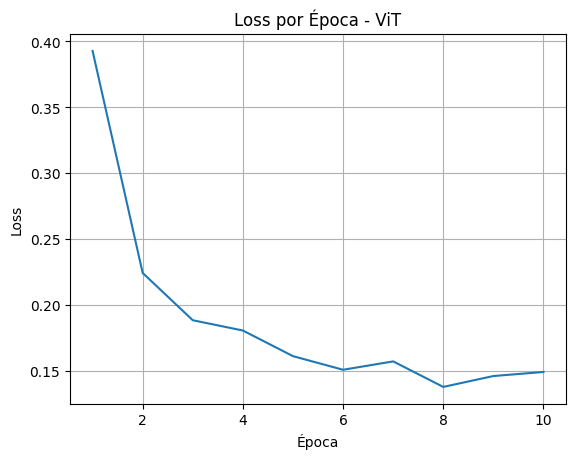

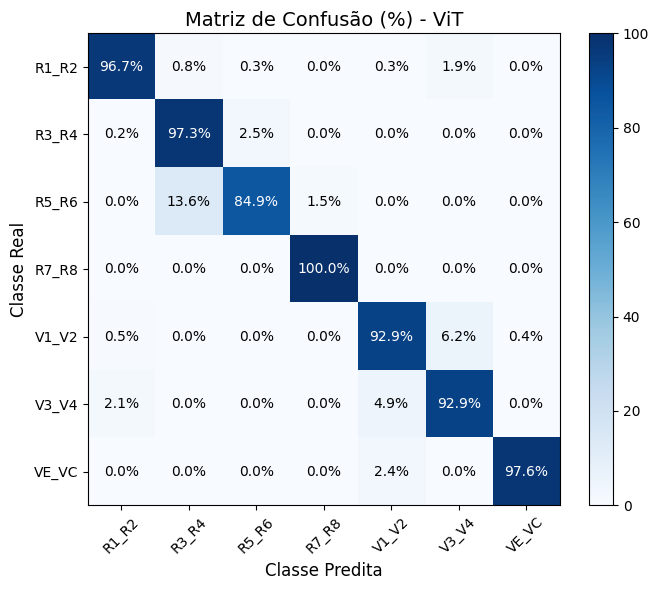

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix

# ===============================
# 📉 Gráfico de Loss
# ===============================
plt.figure()
plt.plot(range(1, len(history_vit["loss"]) + 1), history_vit["loss"])
plt.title("Loss por Época - ViT")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.show()
# ===============================
# 📊 Matriz de Confusão (%) - ViT
# ===============================

vit.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = vit(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 🔹 Matriz absoluta
cm = confusion_matrix(all_labels, all_preds)

# 🔹 Normaliza por linha (percentual por classe real)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))

im = plt.imshow(cm_percent, cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.title("Matriz de Confusão (%) - ViT", fontsize=14)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)

plt.xticks(ticks=np.arange(len(class_names)),
           labels=class_names,
           rotation=45)

plt.yticks(ticks=np.arange(len(class_names)),
           labels=class_names)

# 🔹 Escreve valores nas células
threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        value = cm_percent[i, j]
        plt.text(j, i,
                 f"{value:.1f}%",
                 ha="center",
                 va="center",
                 color="white" if value > threshold else "black",
                 fontsize=10)

plt.tight_layout()
plt.show()


In [ ]:
#EFFICIENTNETV2 — Fine-Tuning Parcial
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

effnet = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1)

num_ftrs = effnet.classifier[1].in_features
effnet.classifier[1] = nn.Linear(num_ftrs, len(class_names))

effnet = effnet.to(DEVICE)

for name, param in effnet.named_parameters():
    if "classifier.1" not in name:
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(effnet.classifier[1].parameters(), lr=1e-3)

history_eff = {"loss": [], "acc": []}

for epoch in range(1, 11):
    loss, acc = train_epoch(effnet, train_loader, criterion, optimizer)
    history_eff["loss"].append(loss)
    history_eff["acc"].append(acc)
    print(f"[EffNetV2] Epoch {epoch} — Loss: {loss:.4f} — Acc: {acc:.4f}")

torch.save(effnet.state_dict(), f"{SAVE_PATH}/efficientnetv2_modeloZera_group.pth")
print("\n✅ EfficientNetV2 salva!")


Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:01<00:00, 45.3MB/s]
/tmp/ipython-input-3664916282.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch:   0%|          | 0/450 [00:00<?, ?it/s]/tmp/ipython-input-3664916282.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[EffNetV2] Epoch 1 — Loss: 0.8364 — Acc: 0.7107


[EffNetV2] Epoch 2 — Loss: 0.6035 — Acc: 0.7743


[EffNetV2] Epoch 3 — Loss: 0.5760 — Acc: 0.7820


[EffNetV2] Epoch 4 — Loss: 0.5450 — Acc: 0.7918


... (2 outputs left out)

[EffNetV2] Epoch 7 — Loss: 0.5367 — Acc: 0.7912


[EffNetV2] Epoch 8 — Loss: 0.5278 — Acc: 0.7942


[EffNetV2] Epoch 9 — Loss: 0.5136 — Acc: 0.7976


[EffNetV2] Epoch 10 — Loss: 0.5250 — Acc: 0.7941

✅ EfficientNetV2 salva!


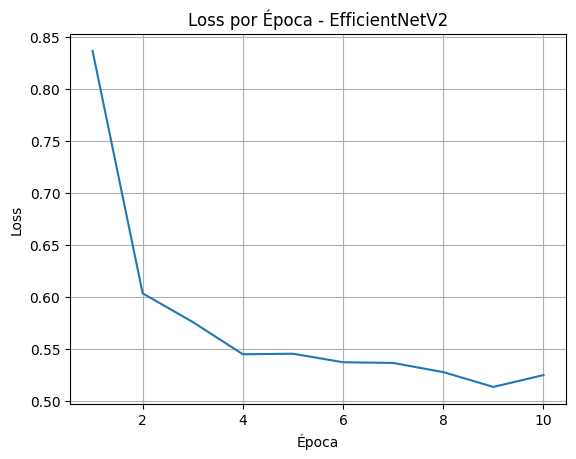

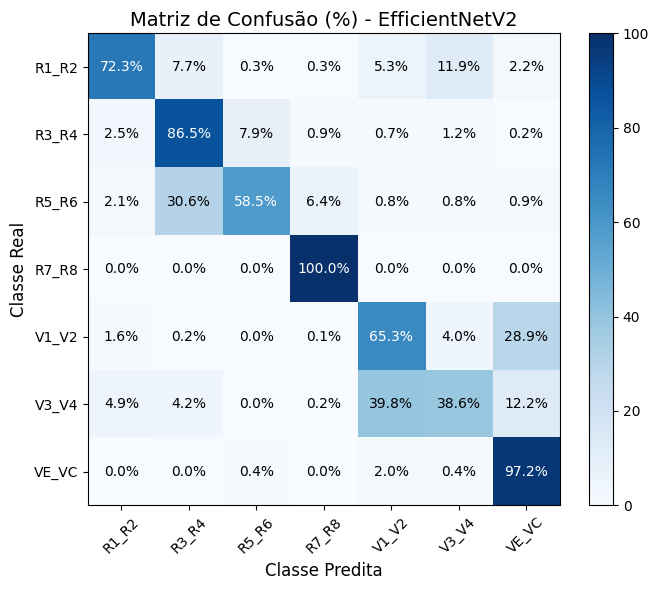

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix

# ===============================
# 📉 Gráfico de Loss
# ===============================
plt.figure()
plt.plot(range(1, len(history_eff["loss"]) + 1), history_eff["loss"])
plt.title("Loss por Época - EfficientNetV2")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ===============================
# 📊 Matriz de Confusão Melhorada
# ===============================

effnet.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = effnet(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Matriz absoluta
cm = confusion_matrix(all_labels, all_preds)

# 🔹 Normaliza por linha (porcentagem por classe real)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))

im = plt.imshow(cm_percent, cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.title("Matriz de Confusão (%) - EfficientNetV2", fontsize=14)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)

plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45)
plt.yticks(ticks=np.arange(len(class_names)), labels=class_names)

# 🔹 Escreve valores nas células
threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        value = cm_percent[i, j]
        plt.text(j, i,
                 f"{value:.1f}%",
                 ha="center",
                 va="center",
                 color="white" if value > threshold else "black",
                 fontsize=10)

plt.grid(False)
plt.tight_layout()
plt.show()


In [ ]:
#RESNET50 — Fine-Tuning Parcial
from torchvision import models

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

# substituir cabeça
num_ftrs = resnet.fc.in_features
resnet.fc = nn.Linear(num_ftrs, len(class_names))

resnet = resnet.to(DEVICE)

# congela tudo, menos a cabeça
for name, param in resnet.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(resnet.fc.parameters(), lr=1e-3)

history_resnet = {"loss": [], "acc": []}

for epoch in range(1, 11):
    loss, acc = train_epoch(resnet, train_loader, criterion, optimizer)
    history_resnet["loss"].append(loss)
    history_resnet["acc"].append(acc)
    print(f"[ResNet] Epoch {epoch} — Loss: {loss:.4f} — Acc: {acc:.4f}")

torch.save(resnet.state_dict(), f"{SAVE_PATH}/resnet50_modeloZera_group.pth")
print("\n✅ ResNet50 salva!")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]
/tmp/ipython-input-3664916282.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch:   0%|          | 0/450 [00:00<?, ?it/s]/tmp/ipython-input-3664916282.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[ResNet] Epoch 1 — Loss: 0.6985 — Acc: 0.7802


[ResNet] Epoch 2 — Loss: 0.4264 — Acc: 0.8594


[ResNet] Epoch 3 — Loss: 0.3590 — Acc: 0.8801


[ResNet] Epoch 4 — Loss: 0.3395 — Acc: 0.8820


... (2 outputs left out)

[ResNet] Epoch 7 — Loss: 0.2885 — Acc: 0.8987


[ResNet] Epoch 8 — Loss: 0.2751 — Acc: 0.9009


[ResNet] Epoch 9 — Loss: 0.2785 — Acc: 0.9012


[ResNet] Epoch 10 — Loss: 0.2753 — Acc: 0.9009

✅ ResNet50 salva!


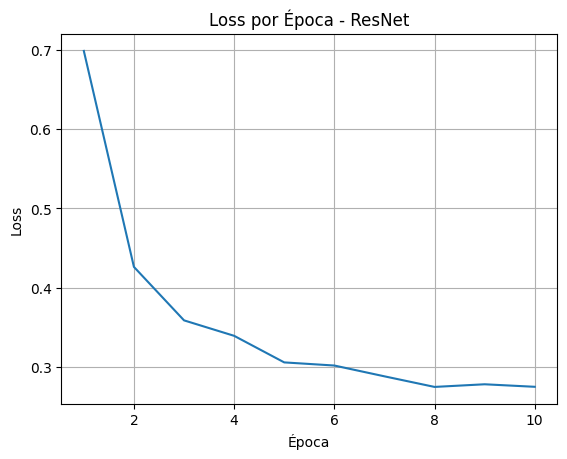

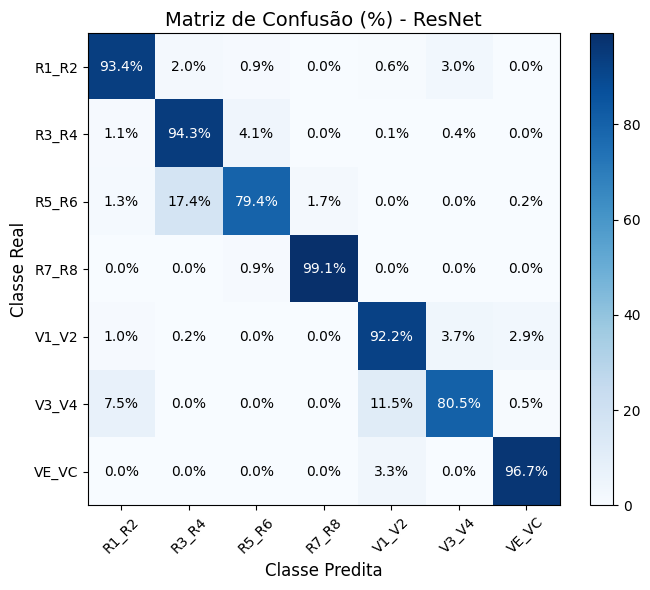

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix

# ===============================
# 📉 Gráfico de Loss - ResNet
# ===============================
plt.figure()
plt.plot(range(1, len(history_resnet["loss"]) + 1), history_resnet["loss"])
plt.title("Loss por Época - ResNet")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# ===============================
# 📊 Matriz de Confusão (%) - ResNet
# ===============================

resnet.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = resnet(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

# 🔹 Normaliza por linha
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))
im = plt.imshow(cm_percent, cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.title("Matriz de Confusão (%) - ResNet", fontsize=14)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        value = cm_percent[i, j]
        plt.text(j, i, f"{value:.1f}%",
                 ha="center", va="center",
                 color="white" if value > threshold else "black",
                 fontsize=10)

plt.tight_layout()
plt.show()


In [ ]:
# ============================
# SWIN TRANSFORMER — Fine-Tuning Parcial
# ============================
import timm

# Criar modelo Swin pré-treinado
swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=len(class_names)
)

swin = swin.to(DEVICE)

# Congelar tudo, menos a cabeça final
for name, param in swin.named_parameters():
    if "head" not in name:
        param.requires_grad = False

# Critério e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(swin.head.parameters(), lr=1e-3)

history_swin = {"loss": [], "acc": []}

# Treinamento
for epoch in range(1, 11):
    loss, acc = train_epoch(swin, train_loader, criterion, optimizer)
    history_swin["loss"].append(loss)
    history_swin["acc"].append(acc)
    print(f"[SWIN] Epoch {epoch} — Loss: {loss:.4f} — Acc: {acc:.4f}")

# Salvar modelo treinado
torch.save(swin.state_dict(), f"{SAVE_PATH}/swin_modeloZera_group.pth")
print("\n✅ Swin Transformer salvo!")


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

/tmp/ipython-input-3664916282.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch:   0%|          | 0/450 [00:00<?, ?it/s]/tmp/ipython-input-3664916282.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[SWIN] Epoch 1 — Loss: 0.5110 — Acc: 0.8251


[SWIN] Epoch 2 — Loss: 0.3114 — Acc: 0.8912


[SWIN] Epoch 3 — Loss: 0.2750 — Acc: 0.9026


[SWIN] Epoch 4 — Loss: 0.2524 — Acc: 0.9127


... (2 outputs left out)

[SWIN] Epoch 7 — Loss: 0.2122 — Acc: 0.9238


[SWIN] Epoch 8 — Loss: 0.2055 — Acc: 0.9315


[SWIN] Epoch 9 — Loss: 0.2058 — Acc: 0.9290


[SWIN] Epoch 10 — Loss: 0.2025 — Acc: 0.9306

✅ Swin Transformer salvo!


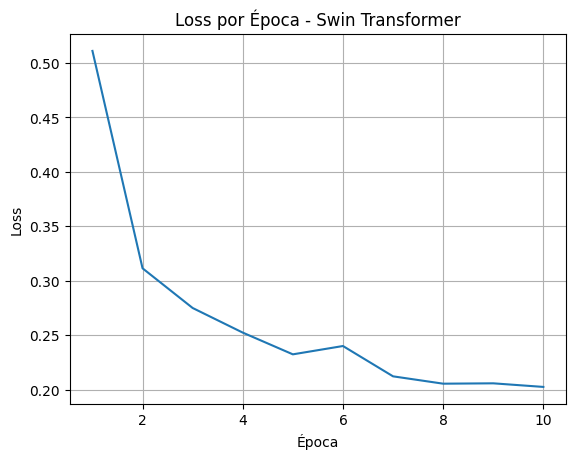

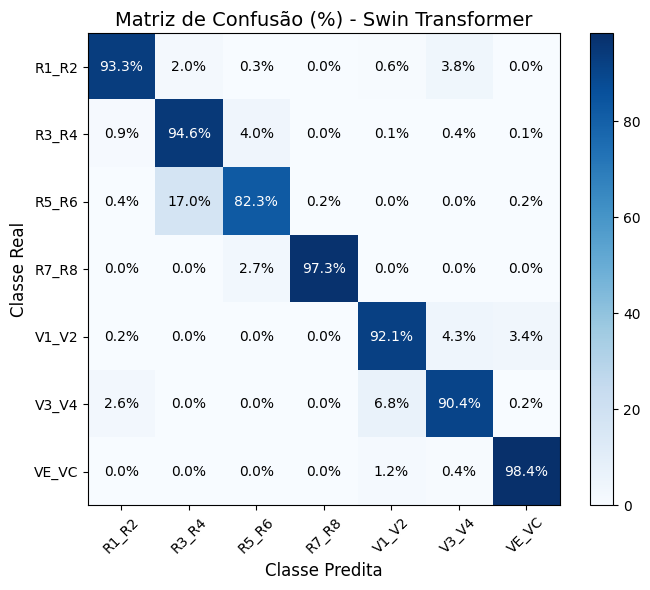

In [ ]:
# ===============================
# 📉 Gráfico de Loss - Swin
# ===============================
plt.figure()
plt.plot(range(1, len(history_swin["loss"]) + 1), history_swin["loss"])
plt.title("Loss por Época - Swin Transformer")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# ===============================
# 📊 Matriz de Confusão (%) - Swin
# ===============================

swin.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = swin(images)  # ✅ corrigido
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))
im = plt.imshow(cm_percent, cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.title("Matriz de Confusão (%) - Swin Transformer", fontsize=14)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        value = cm_percent[i, j]
        plt.text(j, i, f"{value:.1f}%",
                 ha="center", va="center",
                 color="white" if value > threshold else "black",
                 fontsize=10)

plt.tight_layout()
plt.show()


In [ ]:
# ============================
# CONVNEXT BASE — Fine-Tuning Parcial
# ============================
import timm

# Criar modelo ConvNeXt pré-treinado
convnext = timm.create_model(
    "convnext_base",
    pretrained=True,
    num_classes=len(class_names)
)

convnext = convnext.to(DEVICE)

# Congelar tudo, menos a camada final "head"
for name, param in convnext.named_parameters():
    if "head" not in name:   # ConvNeXt usa 'head' como última camada
        param.requires_grad = False

# Critério e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(convnext.head.parameters(), lr=1e-3)

history_conv = {"loss": [], "acc": []}

# Treinamento
for epoch in range(1, 11):
    loss, acc = train_epoch(convnext, train_loader, criterion, optimizer)
    history_conv["loss"].append(loss)
    history_conv["acc"].append(acc)
    print(f"[ConvNeXt] Epoch {epoch} — Loss: {loss:.4f} — Acc: {acc:.4f}")

# Salvar modelo treinado
torch.save(convnext.state_dict(), f"{SAVE_PATH}/convnext_modeloZera_group.pth")
print("\n✅ ConvNeXt salvo!")


model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

/tmp/ipython-input-3664916282.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch:   0%|          | 0/450 [00:00<?, ?it/s]/tmp/ipython-input-3664916282.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[ConvNeXt] Epoch 1 — Loss: 0.3944 — Acc: 0.8593


[ConvNeXt] Epoch 2 — Loss: 0.2330 — Acc: 0.9190


[ConvNeXt] Epoch 3 — Loss: 0.1979 — Acc: 0.9311


[ConvNeXt] Epoch 4 — Loss: 0.1774 — Acc: 0.9375


... (2 outputs left out)

[ConvNeXt] Epoch 7 — Loss: 0.1519 — Acc: 0.9443


[ConvNeXt] Epoch 8 — Loss: 0.1427 — Acc: 0.9505


[ConvNeXt] Epoch 9 — Loss: 0.1368 — Acc: 0.9505


[ConvNeXt] Epoch 10 — Loss: 0.1355 — Acc: 0.9536

✅ ConvNeXt salvo!


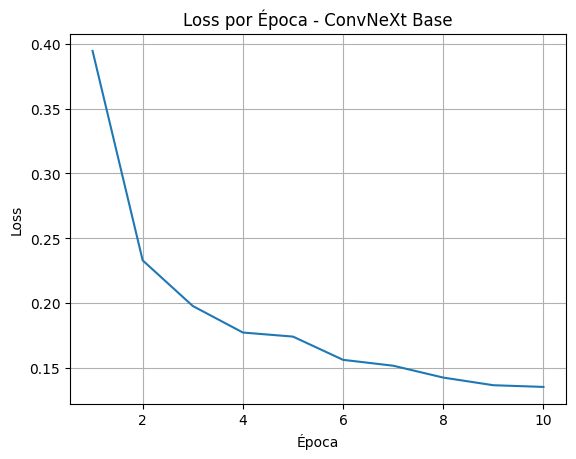

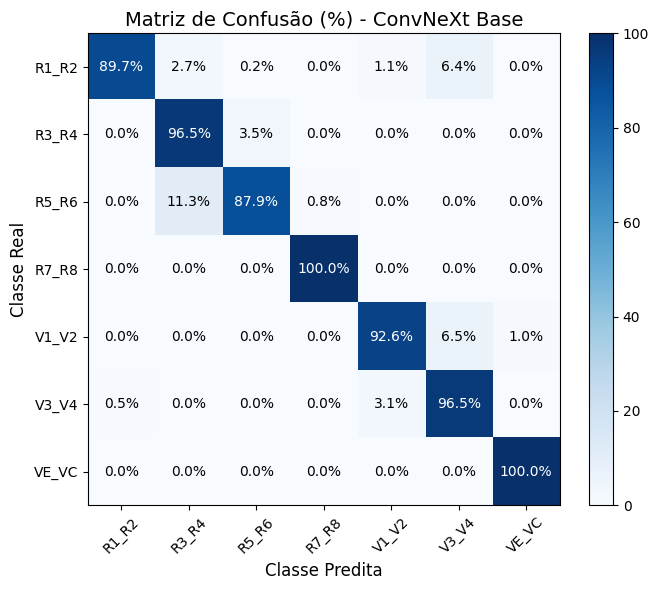

In [ ]:
# ===============================
# 📉 Gráfico de Loss - ConvNeXt
# ===============================
plt.figure()
plt.plot(range(1, len(history_conv["loss"]) + 1), history_conv["loss"])
plt.title("Loss por Época - ConvNeXt Base")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# ===============================
# 📊 Matriz de Confusão (%) - ConvNeXt
# ===============================

convnext.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = convnext(images)  # ✅ correto
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))
im = plt.imshow(cm_percent, cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.title("Matriz de Confusão (%) - ConvNeXt Base", fontsize=14)
plt.xlabel("Classe Predita", fontsize=12)
plt.ylabel("Classe Real", fontsize=12)

plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
plt.yticks(np.arange(len(class_names)), class_names)

threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        value = cm_percent[i, j]
        plt.text(j, i, f"{value:.1f}%",
                 ha="center", va="center",
                 color="white" if value > threshold else "black",
                 fontsize=10)

plt.tight_layout()
plt.show()
